<a href="https://colab.research.google.com/github/SergioCardozoCD/centinela-dengue/blob/main/notebooks/centinela_fase1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Centinela del Dengue · Fase 1 · Línea base con un MLP

**Profundización I: Redes Neuronales y Deep Learning (EA-N-F-004)** · Maestría en Ciencia de Datos · Universidad Santo Tomás · Docente: Javier Mauricio Sierra

**Equipo:** Sergio Alexander Cardozo Ovadia · Cesar Augusto Coy Velandia

**Propuesta de Datos aprobada:** v1, 2026-10-29 (aprobada en el foro el 2026-10-31). Este cuaderno usa exactamente sus fuentes.

**Problema.** Anticipar con una semana de ventaja si un municipio entrará en brote de dengue: la incidencia semanal de la semana *t + 1* supera el límite superior de su canal endémico (método de cuartiles, misma semana de los 5 años previos). Cliente: programas de Enfermedades Transmitidas por Vectores (ETV) de 10 municipios.

**Política de datos.** Los casos de SIVIGILA son datos de salud (Ley 1581 de 2012, art. 5). El cuaderno los descarga de la fuente primaria (API del portal SIVIGILA del INS), los agrega en memoria por municipio y semana y descarta los microdatos. Ninguna salida muestra registros individuales ni tablas de casos semana a semana.

**Uso de IA.** El equipo usó Claude (Anthropic) como asistente; las decisiones y los fallos de la IA están en `bitacora/bitacora-ia.md`. El identificador de cada entrada aparece como comentario en el código que cambió (`# E-n`).

## 0. Preparación del entorno

Se instalan dos lectores (`python-calamine` para leer los Excel del INS mucho más rápido que `openpyxl`, y `pyreadr` para las proyecciones de población en formato `.rds`) y se fijan las semillas de `numpy` y `torch` para que cada ejecución sea reproducible.

In [1]:
# Celda 0 · Entorno, semillas y configuración
!pip -q install python-calamine pyreadr

import io, os, hashlib, datetime, time, warnings
import numpy as np
import pandas as pd
import requests
import torch

warnings.filterwarnings("ignore")
SEMILLA = 2026
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

FECHA_EJECUCION = datetime.date.today().isoformat()
ANIOS = list(range(2007, 2026))           # 2007-2025

# Los 10 municipios del subconjunto 10_municipalities de PhysioNet (DIVIPOLA)
# con coordenadas aproximadas del casco urbano (para NASA POWER)
MUNICIPIOS = pd.DataFrame([
    ("05001", "Medellín",       6.2442, -75.5812),
    ("05360", "Itagüí",         6.1719, -75.6114),
    ("08001", "Barranquilla",  10.9685, -74.7813),
    ("23001", "Montería",       8.7479, -75.8814),
    ("41001", "Neiva",          2.9273, -75.2819),
    ("50001", "Villavicencio",  4.1420, -73.6266),
    ("54001", "Cúcuta",         7.8939, -72.5078),
    ("68001", "Bucaramanga",    7.1193, -73.1227),
    ("73001", "Ibagué",         4.4389, -75.2322),
    ("76001", "Cali",           3.4516, -76.5320),
], columns=["divipola", "municipio", "lat", "lon"])

# Registro de procedencia (Anexo B de la Propuesta): un archivo por fila
procedencia = []
def registrar(archivo, url, contenido_bytes):
    procedencia.append({
        "archivo": archivo,
        "url": url,
        "fecha_descarga": FECHA_EJECUCION,
        "sha256": hashlib.sha256(contenido_bytes).hexdigest(),
    })

print("pandas", pd.__version__, "| torch", torch.__version__, "| fecha", FECHA_EJECUCION)
MUNICIPIOS

pandas 2.2.3 | torch 2.11.0+cpu | fecha 2026-11-03


,divipola,municipio,lat,lon
0,05001,Medellín,6.2442,-75.5812
1,05360,Itagüí,6.1719,-75.6114
2,08001,Barranquilla,10.9685,-74.7813
3,23001,Montería,8.7479,-75.8814
4,41001,Neiva,2.9273,-75.2819
5,50001,Villavicencio,4.1420,-73.6266
6,54001,Cúcuta,7.8939,-72.5078
7,68001,Bucaramanga,7.1193,-73.1227
8,73001,Ibagué,4.4389,-75.2322
9,76001,Cali,3.4516,-76.5320


## 1. Calendario epidemiológico

Colombia usa el mismo calendario que el CDC (semanas MMWR): cada semana va de domingo a sábado, y la semana 1 es la que contiene el 4 de enero. Con esa regla, 2008, 2014, 2020 y 2025 tienen 53 semanas. Se valida con dos hechos conocidos: la semana 1 de 2016 empieza el 2016-01-03 (el nombre del primer archivo de PhysioNet) y la semana 53 de 2025 existe.

In [2]:
# Celda 1 · Calendario epidemiológico (domingo a sábado; la semana 1 contiene el 4 de enero)
def inicio_anio_epi(anio):
    cuatro_enero = pd.Timestamp(anio, 1, 4)
    return cuatro_enero - pd.Timedelta(days=(cuatro_enero.weekday() + 1) % 7)

def semana_epi(fecha):
    fecha = pd.Timestamp(fecha)
    anio = fecha.year
    if fecha < inicio_anio_epi(anio):
        anio -= 1
    elif fecha >= inicio_anio_epi(anio + 1):
        anio += 1
    return anio, (fecha - inicio_anio_epi(anio)).days // 7 + 1

def semanas_del_anio(anio):
    return (inicio_anio_epi(anio + 1) - inicio_anio_epi(anio)).days // 7

assert inicio_anio_epi(2016) == pd.Timestamp("2016-01-03")
assert semanas_del_anio(2025) == 53 and semanas_del_anio(2024) == 52
print("Años con 53 semanas:", [a for a in ANIOS if semanas_del_anio(a) == 53])

Años con 53 semanas: [2008, 2014, 2020, 2025]


## 2. Fuente 1 · SIVIGILA (Instituto Nacional de Salud)

La celda consulta la lista `Microdatos` del portal SIVIGILA (la misma API que usa por dentro el paquete de R `sivirep`), descarga los archivos de **Dengue (210)** y **Dengue Grave (220)** de 2007 a 2025, calcula la huella SHA-256 de cada archivo y los reduce de inmediato a conteos por municipio de procedencia y semana. El evento 580 (mortalidad por dengue) se excluye para no contar dos veces (`# E-4`) y se descartan los casos con ajuste 6 o D (`# E-3`).

La descarga tarda varios minutos (son 38 archivos de Excel). Los conteos agregados quedan en caché en `/content/cache/` para no repetirla si la celda se vuelve a correr.

In [3]:
# Celda 2 · Descarga de SIVIGILA desde la API del INS y agregación municipio-semana

BASE = "https://portalsivigila.ins.gov.co/_api/"
EVENTOS = {"dengue": 210, "dengue grave": 220}   # E-4: el 580 (mortalidad) no se cuenta
COLUMNAS = ["cod_eve", "ano", "semana", "cod_dpto_o", "cod_mun_o", "ajuste"]
os.makedirs("/content/cache", exist_ok=True)
CACHE_SIV = "/content/cache/sivigila_conteos.csv"
CACHE_PROC = "/content/cache/sivigila_procedencia.csv"

def normalizar(col):
    return str(col).strip().lower().rstrip("_")   # el INS publica AJUSTE_, COD_EVE...

def archivos_del_anio(anio):
    consulta = (f"web/lists/GetByTitle('Microdatos')/items?$select=NombreEvento,A_x00f1_o,FileRef"
                f"&$filter=A_x00f1_o%20eq%20%27{anio}%27&$top=5000")
    r = requests.get(BASE + consulta, headers={"Accept": "application/json;odata=verbose"}, timeout=120)
    r.raise_for_status()
    return [(it["NombreEvento"], it["FileRef"]) for it in r.json()["d"]["results"]
            if it["NombreEvento"].strip().lower() in EVENTOS]

def leer_excel(contenido):
    try:
        return pd.read_excel(io.BytesIO(contenido), engine="calamine", dtype=str,
                             usecols=lambda c: normalizar(c) in COLUMNAS)
    except Exception:
        return pd.read_excel(io.BytesIO(contenido), engine="openpyxl", dtype=str,
                             usecols=lambda c: normalizar(c) in COLUMNAS)

if os.path.exists(CACHE_SIV):
    conteos = pd.read_csv(CACHE_SIV, dtype={"divipola": str})
    procedencia += pd.read_csv(CACHE_PROC).to_dict("records")
    crudeza = None
    print("Conteos leídos de la caché.")
else:
    partes, crudeza_filas = [], []
    for anio in ANIOS:
        for evento, ruta in archivos_del_anio(anio):
            url = BASE + f"Web/GetFileByServerRelativeUrl('{ruta}')/$value?binaryStringResponseBody=true"
            contenido = requests.get(url, timeout=600).content
            registrar(ruta.split("/")[-1], url, contenido)
            df = leer_excel(contenido)
            df.columns = [normalizar(c) for c in df.columns]
            assert set(COLUMNAS) <= set(df.columns), f"Faltan columnas en {ruta}"   # E-3: fallar en voz alta
            crudeza_filas.append({"anio": anio, "evento": evento, "filas": len(df),
                                  "vacios_pct": round(100 * df[COLUMNAS].isna().mean().mean(), 2)})
            df["ajuste"] = df["ajuste"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
            df = df[~df["ajuste"].isin(["6", "D"])]                                   # E-3: sin descartados
            df["divipola"] = (pd.to_numeric(df["cod_dpto_o"], errors="coerce").astype("Int64").astype(str).str.zfill(2)
                              + pd.to_numeric(df["cod_mun_o"], errors="coerce").astype("Int64").astype(str).str.zfill(3))
            df = df[df["divipola"].isin(MUNICIPIOS["divipola"])]
            df["anio"] = pd.to_numeric(df["ano"], errors="coerce").astype(int)
            df["semana"] = pd.to_numeric(df["semana"], errors="coerce").astype(int)
            partes.append(df.groupby(["divipola", "anio", "semana"]).size().rename("casos").reset_index())
            del df, contenido                                                         # se descartan los microdatos
        print(f"{anio} listo")
    conteos = (pd.concat(partes).groupby(["divipola", "anio", "semana"], as_index=False)["casos"].sum())
    crudeza = pd.DataFrame(crudeza_filas)
    conteos.to_csv(CACHE_SIV, index=False)
    pd.DataFrame(procedencia).to_csv(CACHE_PROC, index=False)

# Rejilla completa municipio × semana epidemiológica: las semanas sin casos valen 0
rejilla = pd.DataFrame([(d, a, s) for d in MUNICIPIOS["divipola"] for a in ANIOS
                        for s in range(1, semanas_del_anio(a) + 1)],
                       columns=["divipola", "anio", "semana"])
serie = (rejilla.merge(conteos, on=["divipola", "anio", "semana"], how="left")
                .fillna({"casos": 0}).astype({"casos": int}))
print("Tabla municipio-semana:", serie.shape)

2007 listo
2008 listo
2009 listo
2010 listo
2011 listo
2012 listo
2013 listo
2014 listo
2015 listo
2016 listo
2017 listo
2018 listo
2019 listo
2020 listo
2021 listo
2022 listo
2023 listo
2024 listo
2025 listo
Tabla municipio-semana: (9920, 4)


In [4]:
# Celda 3 · Huella de crudeza y verificación cruzada con el script de R (scripts/01_descarga_sivigila.R)
if crudeza is not None:
    print("Filas crudas por evento (todo el país):")
    print(crudeza.groupby("evento")["filas"].sum().to_string())
    print("Total de casos crudos 210 + 220:", crudeza["filas"].sum(), "| vacíos promedio en las 6 columnas:",
          crudeza["vacios_pct"].mean().round(2), "%")

# Totales 2007-2025 obtenidos el 2026-10-30 con el script de R (SALIDA D)
TOTALES_R = {"05001": 57343, "05360": 8476, "08001": 48572, "23001": 20752, "41001": 39613,
             "50001": 54620, "54001": 52647, "68001": 58808, "73001": 58367, "76001": 164047}
verificacion = (serie.groupby("divipola")["casos"].sum().rename("python").to_frame()
                .assign(r=pd.Series(TOTALES_R))
                .assign(diferencia=lambda d: d["python"] - d["r"])
                .join(MUNICIPIOS.set_index("divipola")["municipio"]))
print(verificacion.to_string())
print("¿Coincide con R en los 10 municipios?", bool((verificacion["diferencia"] == 0).all()))

Filas crudas por evento (todo el país):
evento
Dengue          1705604
Dengue Grave      50101
Total de casos crudos 210 + 220: 1755705 | vacíos promedio en las 6 columnas: 0.0 %
          python       r  diferencia      municipio
divipola                                           
05001      57343   57343           0       Medellín
05360       8476    8476           0         Itagüí
08001      48572   48572           0   Barranquilla
23001      20752   20752           0       Montería
41001      39613   39613           0          Neiva
50001      54620   54620           0  Villavicencio
54001      52647   52647           0         Cúcuta
68001      58808   58808           0    Bucaramanga
73001      58367   58367           0         Ibagué
76001     164047  164047           0           Cali
¿Coincide con R en los 10 municipios? True


## 3. Fuente 2 · Clima de NASA POWER

Clima diario por coordenadas (API de NASA POWER, comunidad AG): temperatura media, máxima y mínima a 2 m, humedad relativa y precipitación corregida. Se agrega a semana epidemiológica: promedios para temperatura y humedad, suma para la lluvia. Cada respuesta de la API queda registrada con su huella SHA-256.

In [5]:
# Celda 4 · Clima diario de NASA POWER agregado a semana epidemiológica
PARAMS = "T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR"
CACHE_CLIMA = "/content/cache/clima_semanal.csv"

CACHE_CLIMA_PROC = "/content/cache/clima_procedencia.csv"   # huellas SHA-256 del clima, para que viajen con la caché

if os.path.exists(CACHE_CLIMA) and os.path.exists(CACHE_CLIMA_PROC):
    clima = pd.read_csv(CACHE_CLIMA, dtype={"divipola": str})
    procedencia += pd.read_csv(CACHE_CLIMA_PROC).to_dict("records")
    print("Clima leído de la caché.")
else:
    tablas = []
    for _, m in MUNICIPIOS.iterrows():
        url = ("https://power.larc.nasa.gov/api/temporal/daily/point"
               f"?parameters={PARAMS}&community=AG&longitude={m.lon}&latitude={m.lat}"
               f"&start=20061231&end=20260103&format=JSON")
        r = requests.get(url, timeout=300)
        r.raise_for_status()
        registrar(f"nasa_power_{m.divipola}.json", url, r.content)
        datos = pd.DataFrame(r.json()["properties"]["parameter"])
        datos.index = pd.to_datetime(datos.index, format="%Y%m%d")
        datos = datos.replace(-999, np.nan)
        datos["divipola"] = m.divipola
        tablas.append(datos)
        time.sleep(1)
    diario = pd.concat(tablas).rename_axis("fecha").reset_index()
    diario[["anio", "semana"]] = pd.DataFrame(diario["fecha"].map(semana_epi).tolist(), index=diario.index)
    clima = (diario.groupby(["divipola", "anio", "semana"])
             .agg(t2m=("T2M", "mean"), t2m_max=("T2M_MAX", "mean"), t2m_min=("T2M_MIN", "mean"),
                  rh2m=("RH2M", "mean"), lluvia=("PRECTOTCORR", "sum"), dias=("T2M", "size"))
             .reset_index())
    clima = clima[clima["anio"].isin(ANIOS)]
    clima.to_csv(CACHE_CLIMA, index=False)
    pd.DataFrame([p for p in procedencia if p["archivo"].startswith("nasa_power")]).to_csv(CACHE_CLIMA_PROC, index=False)

print("Clima semanal:", clima.shape)
print("Semanas con menos de 7 días de datos:", int((clima["dias"] < 7).sum()))
print(clima.drop(columns=["anio", "semana", "dias"]).groupby("divipola").mean().round(1).to_string())

Clima semanal: (9920, 9)
Semanas con menos de 7 días de datos: 0
           t2m  t2m_max  t2m_min  rh2m  lluvia
divipola                                      
05001     17.8     22.0     14.8  87.8    42.4
05360     17.8     22.0     14.8  87.8    42.4
08001     27.9     30.6     26.2  80.6    25.4
23001     27.8     33.7     23.8  80.0    28.5
41001     20.3     25.4     16.5  79.6    26.4
50001     19.1     23.1     16.0  87.5    50.4
54001     26.0     32.4     21.2  64.4    15.0
68001     20.2     25.8     16.1  76.3    24.8
73001     22.9     27.8     18.8  75.2    31.6
76001     16.3     21.3     12.6  84.4    22.5


## 4. Fuente 3 · Población (proyecciones DANE)

Denominador de la incidencia. Son las proyecciones municipales del DANE que publica el equipo de `sivirep` (repositorio TRACE-LAC/sivirep_incidence), un archivo `.rds` por año. Se usa el total del municipio (cabecera más rural, todas las edades).

In [6]:
# Celda 5 · Población municipal por año (DANE vía sivirep)
import pyreadr, tempfile
URL_POB = "https://raw.githubusercontent.com/TRACE-LAC/sivirep_incidence/main/data/proyecciones/proyecciones_{anio}.rds"
poblacion = []
for anio in ANIOS:
    url = URL_POB.format(anio=anio)
    contenido = requests.get(url, timeout=300).content
    registrar(f"proyecciones_{anio}.rds", url, contenido)
    with tempfile.NamedTemporaryFile(suffix=".rds") as tmp:
        tmp.write(contenido); tmp.flush()
        df = list(pyreadr.read_r(tmp.name).values())[0]
    df = df[(df["area_geografica"] == "Total") & (df["mpio"].isin(MUNICIPIOS["divipola"]))]
    poblacion.append(df.groupby("mpio")["total"].sum().rename("poblacion").reset_index()
                     .rename(columns={"mpio": "divipola"}).assign(anio=anio))
poblacion = pd.concat(poblacion)
print(poblacion.pivot(index="anio", columns="divipola", values="poblacion").loc[sorted({ANIOS[0], 2016, ANIOS[-1]})].astype(int).to_string())

divipola    05001   05360    08001   23001   41001   50001   54001   68001   73001    76001
anio                                                                                       
2007      2101771  230020  1106754  432186  314910  421747  631419  500260  482895  2114530
2016      2351077  266257  1167555  478806  349048  512462  680030  562123  520856  2195915
2025      2634570  301428  1342818  531424  388229  593273  815891  623881  546003  2285099


## 5. Fuente 4 · Imagen de muestra de PhysioNet (solo procedencia)

Las imágenes se modelan en la Fase 2. Aquí solo se descarga una escena para dejar su huella SHA-256 en el Anexo B. **Versión usada: PhysioNet 1.0.0** (DOI versionado 10.13026/xr5s-xe24, publicada el 2024-01-30), porque es la versión con la que se hizo la prueba de acoplamiento del Anexo A y la que cita la Propuesta aprobada; un DOI versionado garantiza que los archivos no cambian. Al 2026-11-01 es la única versión publicada; dentro de ella, la carpeta `81_municipalities_v2.0` trae una limpieza de imágenes negras distinta (forward-backward), que se evaluará en la Fase 2. Aquí se usa `10_municipalities`.

In [7]:
# Celda 6 · Huella de una escena de PhysioNet 1.0.0
URL_IMG = ("https://physionet.org/files/multimodal-satellite-data/1.0.0/"
           "10_municipalities/images/8001/image_2016-01-03.tiff")
r = requests.get(URL_IMG, timeout=300)
print("Código:", r.status_code, "| bytes:", len(r.content))
registrar("10_municipalities/images/8001/image_2016-01-03.tiff", URL_IMG, r.content)

Código: 200 | bytes: 3489977


## 6. Tabla integrada y cadena de procedencia (Anexo B)

Se unen las tres fuentes por (municipio, año, semana) y se calcula la incidencia por 100.000 habitantes. La tabla queda solo en memoria y en la caché de la sesión de Colab; no se guarda en el repositorio.

In [8]:
# Celda 7 · Tabla integrada municipio-semana e incidencia
datos = (serie.merge(clima.drop(columns="dias"), on=["divipola", "anio", "semana"], how="left")
              .merge(poblacion, on=["divipola", "anio"], how="left")
              .merge(MUNICIPIOS[["divipola", "municipio"]], on="divipola"))
datos["incidencia"] = 100_000 * datos["casos"] / datos["poblacion"]
datos = datos.sort_values(["divipola", "anio", "semana"]).reset_index(drop=True)

print("Filas × columnas:", datos.shape)
print("Vacíos por columna (%):")
print((100 * datos.isna().mean()).round(2).to_string())
print("\nIncidencia semanal por 100.000 hab. (resumen por municipio):")
print(datos.groupby("municipio")["incidencia"].describe()[["mean", "50%", "max"]].round(2).to_string())

# Cadena de procedencia: archivos y huellas (Anexo B, punto 1)
tabla_procedencia = pd.DataFrame(procedencia)
print("\nArchivos registrados:", len(tabla_procedencia))
tabla_procedencia.assign(sha256=lambda d: d["sha256"].str[:16] + "…")[["archivo", "fecha_descarga", "sha256"]]

Filas × columnas: (9920, 12)
Vacíos por columna (%):
divipola      0.0
anio          0.0
semana        0.0
casos         0.0
t2m           0.0
t2m_max       0.0
t2m_min       0.0
rh2m          0.0
lluvia        0.0
poblacion     0.0
municipio     0.0
incidencia    0.0

Incidencia semanal por 100.000 hab. (resumen por municipio):
                mean   50%    max
municipio                        
Barranquilla    3.99  2.35  36.00
Bucaramanga    10.59  7.09  73.75
Cali            7.44  3.74  57.23
Cúcuta          7.58  6.38  27.85
Ibagué         11.26  4.95  84.35
Itagüí          3.36  0.41  97.46
Medellín        2.49  0.85  37.52
Montería        4.15  2.11  69.44
Neiva          11.38  8.08  81.20
Villavicencio  10.61  8.60  58.09

Archivos registrados: 68


,archivo,fecha_descarga,sha256
0,Datos_2007_220.xlsx,2026-11-03,d6f3d5996784409f…
1,Datos_2007_210.xlsx,2026-11-03,9a6e8847af35cd1b…
2,Datos_2008_220.xlsx,2026-11-03,90f19e58f4f8b959…
3,Datos_2008_210.xlsx,2026-11-03,e550c7ff0467a79d…
4,Datos_2009_220.xlsx,2026-11-03,47f13c43cce3593c…
...,...,...,...
63,proyecciones_2022.rds,2026-11-03,3b2ec762df438bb0…
64,proyecciones_2023.rds,2026-11-03,376f0ee01abf7d3c…
65,proyecciones_2024.rds,2026-11-03,91f9224d8d7a8bdb…
66,proyecciones_2025.rds,2026-11-03,61a9e875cbed3ba3…


In [9]:
# Celda 8 · Canal endémico (método de cuartiles) y etiqueta de brote
VENTANA_ANIOS = 5          # misma semana de los 5 años previos
MIN_CASOS = 5              # mínimo de casos para la variante con piso (punto 2 del profe)

datos["semana_ref"] = datos["semana"].clip(upper=52)   # la semana 53 se compara con la 52 de años previos
pivote = datos.pivot_table(index=["divipola", "semana_ref"], columns="anio", values="incidencia", aggfunc="mean")

def q3_previo(fila):
    previos = [a for a in range(fila.anio - VENTANA_ANIOS, fila.anio) if a in pivote.columns]
    if len(previos) < VENTANA_ANIOS:
        return np.nan
    return np.nanpercentile(pivote.loc[(fila.divipola, fila.semana_ref), previos].values, 75)

datos["q3_canal"] = datos.apply(q3_previo, axis=1)
datos["brote_t"] = (datos["incidencia"] > datos["q3_canal"]).astype(float).where(datos["q3_canal"].notna())
datos["brote_t_min5"] = ((datos["incidencia"] > datos["q3_canal"]) & (datos["casos"] >= MIN_CASOS)).astype(float).where(datos["q3_canal"].notna())

# Objetivo: brote en la semana siguiente (t + 1), dentro de cada municipio
datos = datos.sort_values(["divipola", "anio", "semana"]).reset_index(drop=True)
for col in ["brote_t", "brote_t_min5"]:
    datos[col.replace("_t", "_t1")] = datos.groupby("divipola")[col].shift(-1)

etiquetado = datos.dropna(subset=["brote_t1"])
print("Semanas con etiqueta:", len(etiquetado), "| desde", etiquetado["anio"].min(), "hasta", etiquetado["anio"].max())
print("Balance de la etiqueta brote(t+1):")
print("  sin piso de casos :", f"{etiquetado['brote_t1'].mean():.1%}")
print(f"  con piso de {MIN_CASOS} casos:", f"{etiquetado['brote_t1_min5'].mean():.1%}")

Semanas con etiqueta: 7310 | desde 2011 hasta 2025
Balance de la etiqueta brote(t+1):
  sin piso de casos : 36.6%
  con piso de 5 casos: 35.6%


In [10]:
# Celda 8b · Estilo único para todas las gráficas del cuaderno
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Un color = un significado, en todo el cuaderno
AZUL    = "#2a78d6"   # el dato principal (incidencia, la etiqueta que usaremos)
NARANJA = "#eb6834"   # lo que pide atención (brotes, años de pandemia)
GRIS    = "#c9c8c3"   # referencia o comparación (barras de contexto)
TINTA   = "#52514e"   # textos, ejes y líneas de referencia
REJILLA = "#e6e5e1"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 9, "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelcolor": TINTA, "axes.labelsize": 9,
    "text.color": TINTA, "xtick.color": TINTA, "ytick.color": TINTA,
    "axes.edgecolor": GRIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.fontsize": 8.5, "lines.linewidth": 1.8,
    "lines.solid_capstyle": "round",
})
print("Estilo listo")

Estilo listo


              brote_sin_piso brote_con_piso q3_igual_cero semanas_menos_5_casos  semanas
municipio                                                                               
Montería              52.0 %         51.7 %         0.0 %                14.1 %      731
Villavicencio         38.0 %         38.0 %         0.0 %                 1.0 %      731
Barranquilla          37.1 %         37.1 %         0.0 %                 6.6 %      731
Cúcuta                36.9 %         36.9 %         0.0 %                 2.9 %      731
Ibagué                36.8 %         36.8 %         0.0 %                 5.7 %      731
Neiva                 36.7 %         36.7 %         0.0 %                 5.7 %      731
Medellín              35.7 %         35.7 %         0.0 %                10.4 %      731
Cali                  34.7 %         34.7 %         0.0 %                 0.0 %      731
Bucaramanga           31.5 %         31.5 %         0.0 %                 8.5 %      731
Itagüí               

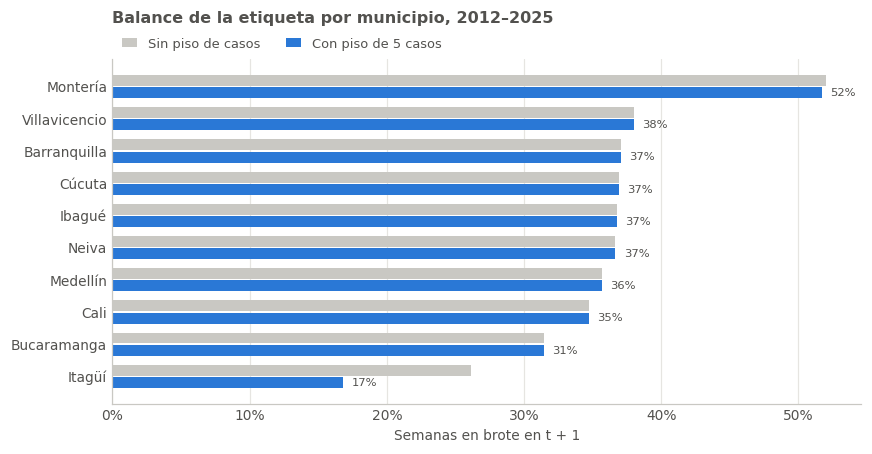

In [11]:
# Celda 9 · EDA: balance de la etiqueta por municipio y efecto de los conteos bajos (punto 2 del profe)
por_mun = (etiquetado.groupby("municipio")
           .agg(semanas=("brote_t1", "size"),
                brote_sin_piso=("brote_t1", "mean"),
                brote_con_piso=("brote_t1_min5", "mean"),
                q3_igual_cero=("q3_canal", lambda s: (s == 0).mean()),
                semanas_menos_5_casos=("casos", lambda s: (s < MIN_CASOS).mean()))
           .sort_values("brote_sin_piso", ascending=False))
print((por_mun[["brote_sin_piso", "brote_con_piso", "q3_igual_cero", "semanas_menos_5_casos"]] * 100)
      .round(1).astype(str).add(" %").assign(semanas=por_mun["semanas"]).to_string())

fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(por_mun))
ax.barh(y - 0.19, por_mun["brote_sin_piso"], height=0.34, color=GRIS, label="Sin piso de casos")
ax.barh(y + 0.19, por_mun["brote_con_piso"], height=0.34, color=AZUL, label=f"Con piso de {MIN_CASOS} casos")
for yi, v in zip(y, por_mun["brote_con_piso"]):
    ax.text(v + 0.006, yi + 0.19, f"{v:.0%}", va="center", fontsize=7.5, color=TINTA)
ax.set_yticks(y, por_mun.index)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Semanas en brote en t + 1")
ax.set_title("Balance de la etiqueta por municipio, 2012–2025", pad=24)
ax.legend(loc="lower left", ncol=2, bbox_to_anchor=(0, 1.0), borderaxespad=0.3, handlelength=1.2)
plt.tight_layout(); plt.show()

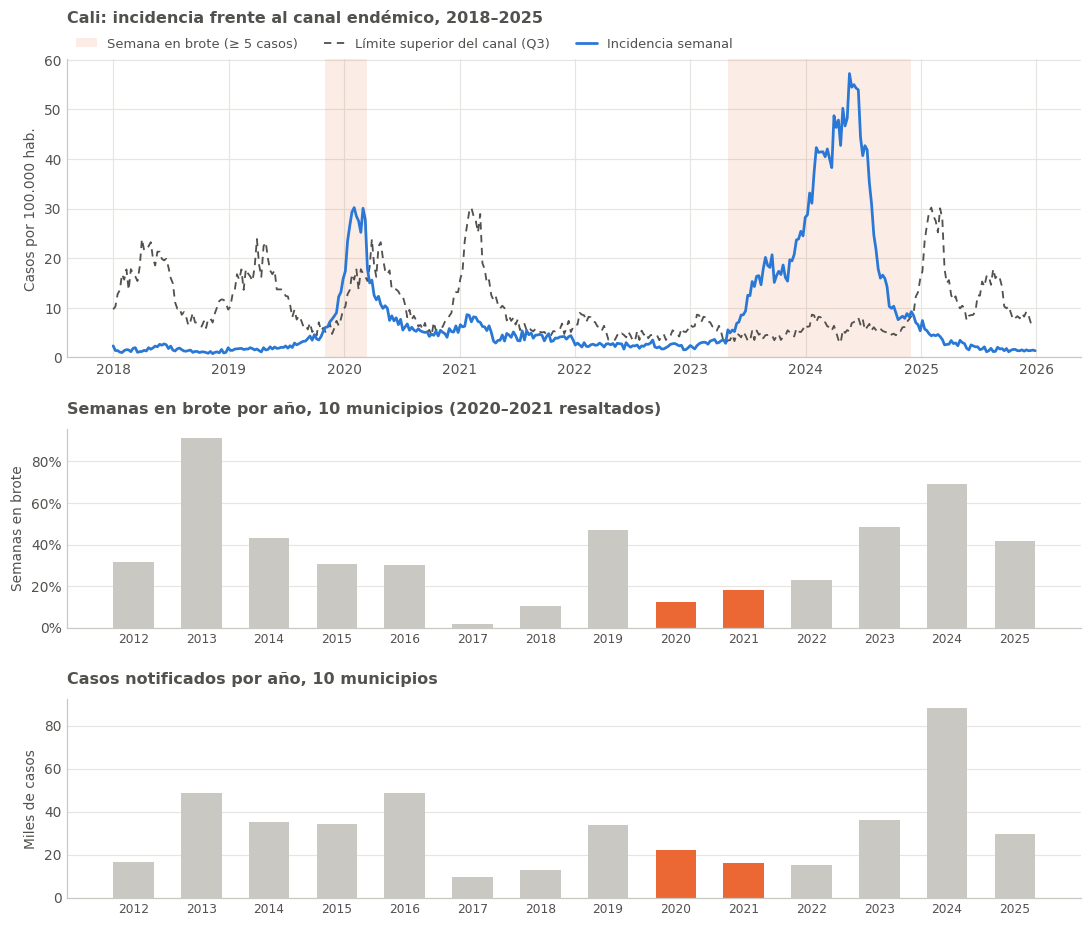

Por año (semana t con su propia etiqueta):
       brote  casos
anio               
2012  31.7 %  16731
2013  91.2 %  48692
2014  43.0 %  35205
2015  30.8 %  34416
2016  30.2 %  48506
2017   1.9 %   9408
2018  10.4 %  12938
2019  46.9 %  33798
2020  12.3 %  22108
2021  17.9 %  15896
2022  23.1 %  15416
2023  48.3 %  36032
2024  69.0 %  88050
2025  41.9 %  29699


In [12]:
# Celda 10 · EDA: cómo se construye la etiqueta (Cali) y el efecto de la pandemia (punto 3 del profe)
ejemplo = datos[(datos["municipio"] == "Cali") & (datos["anio"].between(2018, 2025))].copy()
ejemplo["fecha"] = [inicio_anio_epi(a) + pd.Timedelta(weeks=s - 1) for a, s in zip(ejemplo["anio"], ejemplo["semana"])]

# Por año se cuenta la semana t con su propia etiqueta (brote_t_min5, la regla elegida): así cada año tiene sus 52 o 53 semanas
anual = datos.dropna(subset=["brote_t_min5"]).groupby("anio").agg(brote=("brote_t_min5", "mean"), casos=("casos", "sum"))
colores = [NARANJA if a in (2020, 2021) else GRIS for a in anual.index]

fig, axes = plt.subplots(3, 1, figsize=(10, 8.5), gridspec_kw={"height_ratios": [3, 2, 2]})

ax = axes[0]
techo = ejemplo["incidencia"].max() * 1.05
ax.fill_between(ejemplo["fecha"], 0, techo, where=ejemplo["brote_t_min5"] == 1, color=NARANJA, alpha=0.12,
                step="mid", linewidth=0, label=f"Semana en brote (≥ {MIN_CASOS} casos)")
ax.plot(ejemplo["fecha"], ejemplo["q3_canal"], color=TINTA, lw=1.2, ls=(0, (4, 3)), label="Límite superior del canal (Q3)")
ax.plot(ejemplo["fecha"], ejemplo["incidencia"], color=AZUL, lw=1.8, label="Incidencia semanal")
ax.set_ylim(0, techo)
ax.set_ylabel("Casos por 100.000 hab.")
ax.set_title("Cali: incidencia frente al canal endémico, 2018–2025", pad=24)
ax.legend(loc="lower left", ncol=3, bbox_to_anchor=(0, 1.0), borderaxespad=0.3, handlelength=1.6)

ax = axes[1]
ax.bar(anual.index, anual["brote"], color=colores, width=0.6)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylabel("Semanas en brote")
ax.set_title("Semanas en brote por año, 10 municipios (2020–2021 resaltados)")

ax = axes[2]
ax.bar(anual.index, anual["casos"] / 1000, color=colores, width=0.6)
ax.set_ylabel("Miles de casos")
ax.set_title("Casos notificados por año, 10 municipios")
for a in axes[1:]:
    a.grid(axis="x", visible=False)
    a.set_xticks(anual.index)
    a.tick_params(axis="x", labelsize=8)
plt.tight_layout(h_pad=1.8); plt.show()

print("Por año (semana t con su propia etiqueta):")
print(anual.assign(brote=(anual["brote"] * 100).round(1).astype(str) + " %").to_string())

In [13]:
# Celda 11 · Decisión: etiqueta del modelo = brote en t + 1 con piso de 5 casos (punto 2 del profe)
# Una sola regla para los 10 municipios; en la práctica solo cambia a Itagüí (26,1 % → 16,8 %)
ETIQUETA = "brote_t1_min5"
etiquetado = datos.dropna(subset=[ETIQUETA]).copy()
etiquetado["y"] = etiquetado[ETIQUETA].astype(int)
print("Etiqueta elegida:", ETIQUETA)
print("Filas:", len(etiquetado), "| positivos:", etiquetado["y"].sum(), f"({etiquetado['y'].mean():.1%})")

Etiqueta elegida: brote_t1_min5
Filas: 7310 | positivos: 2602 (35.6%)


In [14]:
# Celda 12 · Variables (features): todo lo que se sabe al cierre de la semana t para predecir t + 1
datos = datos.sort_values(["divipola", "anio", "semana"]).reset_index(drop=True)
g = datos.groupby("divipola")

datos["log_inc"] = np.log1p(datos["incidencia"])                  # la incidencia es muy asimétrica: se usa log(1 + x)
for k in range(1, 5):
    datos[f"log_inc_l{k}"] = g["log_inc"].shift(k)                  # rezagos t-1 … t-4
datos["log_q3_t1"] = np.log1p(g["q3_canal"].shift(-1))             # umbral de t + 1: sale de años previos, se conoce de antemano
datos["anio_obj"] = g["anio"].shift(-1)                            # año de la semana que se predice (para partir por años)

# Clima: promedios de 4 semanas en tres ventanas (0–3, 4–7 y 8–11 semanas atrás); el mosquito responde con rezago
for var in ["t2m", "rh2m", "lluvia"]:
    for desde in (0, 4, 8):
        datos[f"{var}_v{desde}"] = g[var].transform(lambda s, d=desde: s.shift(d).rolling(4).mean())

datos["sem_sin"] = np.sin(2 * np.pi * datos["semana"] / 52)         # estacionalidad: la semana 52 queda junto a la 1
datos["sem_cos"] = np.cos(2 * np.pi * datos["semana"] / 52)
mun_dummies = pd.get_dummies(datos["municipio"], prefix="mun", dtype=float)
datos = pd.concat([datos, mun_dummies], axis=1)

VARS_CONTINUAS = (["log_inc"] + [f"log_inc_l{k}" for k in range(1, 5)] + ["log_q3_t1"]
                  + [f"{v}_v{d}" for v in ["t2m", "rh2m", "lluvia"] for d in (0, 4, 8)] + ["sem_sin", "sem_cos"])
VARS_BINARIAS = ["brote_t_min5"] + list(mun_dummies.columns)       # brote actual + municipio (one-hot)
VARIABLES = VARS_CONTINUAS + VARS_BINARIAS

modelo_df = datos.dropna(subset=[ETIQUETA] + VARIABLES).copy()
modelo_df["y"] = modelo_df[ETIQUETA].astype(int)
print("Variables de entrada:", len(VARIABLES), f"({len(VARS_CONTINUAS)} continuas + {len(VARS_BINARIAS)} binarias)")
print("Filas para el modelo:", len(modelo_df), "| años objetivo:", int(modelo_df["anio_obj"].min()), "–", int(modelo_df["anio_obj"].max()))
print("Vacíos en las variables:", int(modelo_df[VARIABLES].isna().sum().sum()))

Variables de entrada: 28 (17 continuas + 11 binarias)
Filas para el modelo: 7300 | años objetivo: 2012 – 2025
Vacíos en las variables: 0


In [15]:
# Celda 13 · Partición cronológica (por año de la semana que se predice) y estandarización
PARTICIONES = {
    "aprobada":       {"train": range(2012, 2020), "val": [2020, 2021, 2022], "test": [2023, 2024, 2025]},
    "sin_pandemia":   {"train": range(2012, 2019), "val": [2019, 2022],       "test": [2023, 2024, 2025]},
}

def partir(nombre):
    p = PARTICIONES[nombre]
    partes = {k: modelo_df[modelo_df["anio_obj"].isin(list(v))] for k, v in p.items()}
    # La media y la desviación se calculan SOLO con train (si se usa val o test, se filtra información del futuro)
    media = partes["train"][VARS_CONTINUAS].mean()
    desv = partes["train"][VARS_CONTINUAS].std()
    salida = {}
    for k, df in partes.items():
        X = pd.concat([(df[VARS_CONTINUAS] - media) / desv, df[VARS_BINARIAS]], axis=1)[VARIABLES]
        salida[k] = {"df": df, "X": torch.tensor(X.values, dtype=torch.float32),
                     "y": torch.tensor(df["y"].values, dtype=torch.float32).view(-1, 1)}
    return salida

conjuntos = {n: partir(n) for n in PARTICIONES}

filas = []
for n, c in conjuntos.items():
    for k in ["train", "val", "test"]:
        df = c[k]["df"]
        anios = sorted(df["anio_obj"].astype(int).unique())
        texto_anios = f"{anios[0]}–{anios[-1]}" if len(anios) == anios[-1] - anios[0] + 1 else ", ".join(map(str, anios))
        filas.append({"esquema": n, "conjunto": k, "años": texto_anios,
                      "filas": len(df), "brotes": int(df["y"].sum()), "% brote": f"{df['y'].mean():.1%}"})
print(pd.DataFrame(filas).to_string(index=False))
print("\nForma de X_train (esquema aprobado):", tuple(conjuntos["aprobada"]["train"]["X"].shape))

     esquema conjunto       años  filas  brotes % brote
    aprobada    train  2012–2019   4160    1488   35.8%
    aprobada      val  2020–2022   1570     278   17.7%
    aprobada     test  2023–2025   1570     832   53.0%
sin_pandemia    train  2012–2018   3640    1244   34.2%
sin_pandemia      val 2019, 2022   1040     364   35.0%
sin_pandemia     test  2023–2025   1570     832   53.0%

Forma de X_train (esquema aprobado): (4160, 28)


In [16]:
# Celda 14 · Líneas base: lo que el MLP tiene que superar
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

def metricas(df, y_pred):
    y_pred = np.asarray(y_pred).astype(int)
    inicio = ((df["brote_t_min5"] == 0) & (df["y"] == 1)).values   # semanas en que un brote EMPIEZA en t + 1
    return {"exactitud": accuracy_score(df["y"], y_pred),
            "precisión": precision_score(df["y"], y_pred, zero_division=0),
            "recall": recall_score(df["y"], y_pred, zero_division=0),
            "F1": f1_score(df["y"], y_pred, zero_division=0),
            "recall_inicio": y_pred[inicio].mean() if inicio.any() else np.nan,
            "n_inicios": int(inicio.sum())}

filas = []
for k in ["val", "test"]:
    df = conjuntos["aprobada"][k]["df"]
    filas.append({"conjunto": k, "modelo": "Clase mayoritaria (nunca brote)", **metricas(df, np.zeros(len(df)))})
    filas.append({"conjunto": k, "modelo": "Persistencia (brote en t → brote en t+1)", **metricas(df, df["brote_t_min5"])})
lineas_base = pd.DataFrame(filas)
print(lineas_base.round(3).to_string(index=False))

conjunto                                   modelo  exactitud  precisión  recall    F1  recall_inicio  n_inicios
     val          Clase mayoritaria (nunca brote)      0.823      0.000   0.000 0.000            0.0         44
     val Persistencia (brote en t → brote en t+1)      0.942      0.833   0.842 0.837            0.0         44
    test          Clase mayoritaria (nunca brote)      0.470      0.000   0.000 0.000            0.0         73
    test Persistencia (brote en t → brote en t+1)      0.906      0.911   0.912 0.912            0.0         73


In [17]:
# Celda 15 · Arquitectura: MLP 28 → 56 → 28 → 1 (salida en logit)
import copy
import torch.nn as nn

class CentinelaMLP(nn.Module):
    """MLP para clasificación binaria: d → 2d → d → 1.
    Primera capa ≈ 2 × número de variables (regla del profe); la segunda, la mitad.
    La salida NO pasa por sigmoide: devuelve el logit, pareja de BCEWithLogitsLoss.
    La probabilidad se obtiene con torch.sigmoid SOLO al evaluar."""
    def __init__(self, d_entrada, oculta1=None, oculta2=None, p_dropout=0.0):
        super().__init__()
        oculta1 = oculta1 or 2 * d_entrada
        oculta2 = oculta2 or oculta1 // 2
        self.red = nn.Sequential(
            nn.Linear(d_entrada, oculta1), nn.ReLU(), nn.Dropout(p_dropout),
            nn.Linear(oculta1, oculta2),   nn.ReLU(), nn.Dropout(p_dropout),
            nn.Linear(oculta2, 1),          # logit: sin activación final
        )
    def forward(self, x):
        return self.red(x)

torch.manual_seed(SEMILLA)
modelo = CentinelaMLP(len(VARIABLES))
print(modelo)
print("Parámetros entrenables:", f"{sum(p.numel() for p in modelo.parameters()):,}".replace(",", "."))

CentinelaMLP(
  (red): Sequential(
    (0): Linear(in_features=28, out_features=56, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=56, out_features=28, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=28, out_features=1, bias=True)
  )
)
Parámetros entrenables: 3.249


In [18]:
# Celda 16 · Bucle de entrenamiento explícito (5 pasos por lote) con parada temprana
def entrenar(modelo, X_tr, y_tr, X_va, y_va, epocas=50, lr=1e-3, tam_lote=128, semilla=SEMILLA):
    """Entrena con mini-lotes y devuelve {"train": [...], "val": [...], "mejor_epoca": k}.
    En cada época mide la pérdida de validación; cuando marca un nuevo mínimo guarda una copia
    del estado del modelo y, al terminar, la restaura (el modelo final es el de esa época)."""
    criterio = nn.BCEWithLogitsLoss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    generador = torch.Generator().manual_seed(semilla)          # el orden de los lotes también es reproducible
    hist = {"train": [], "val": []}
    mejor_val, mejor_estado, mejor_epoca = float("inf"), None, 0

    for epoca in range(1, epocas + 1):
        modelo.train()                                          # activa el Dropout
        orden = torch.randperm(len(X_tr), generator=generador)
        suma, n = 0.0, 0
        for i in range(0, len(X_tr), tam_lote):
            idx = orden[i:i + tam_lote]
            logits = modelo(X_tr[idx])                          # (1) forward
            perdida = criterio(logits, y_tr[idx])               # (2) pérdida
            optimizador.zero_grad()                             # (3) limpiar gradientes
            perdida.backward()                                  # (4) retropropagación
            optimizador.step()                                  # (5) actualizar pesos
            suma += perdida.item() * len(idx); n += len(idx)
        hist["train"].append(suma / n)

        modelo.eval()                                           # apaga el Dropout para medir
        with torch.no_grad():
            val = criterio(modelo(X_va), y_va).item()
        hist["val"].append(val)
        if val < mejor_val:
            mejor_val, mejor_epoca = val, epoca
            mejor_estado = copy.deepcopy(modelo.state_dict())

    modelo.load_state_dict(mejor_estado)                        # parada temprana: se queda con la mejor época
    hist["mejor_epoca"] = mejor_epoca
    return hist

def graficar_curvas(historiales, titulo):
    """Una o varias corridas lado a lado, con la misma escala y la época óptima marcada."""
    fig, axes = plt.subplots(1, len(historiales), figsize=(5.2 * len(historiales), 3.6), sharey=True, squeeze=False)
    for ax, (nombre, h) in zip(axes[0], historiales.items()):
        ep = np.arange(1, len(h["train"]) + 1)
        ax.plot(ep, h["train"], color=GRIS, lw=1.8, label="Entrenamiento")
        ax.plot(ep, h["val"], color=AZUL, lw=1.8, label="Validación")
        ax.axvline(h["mejor_epoca"], color=NARANJA, lw=1, ls=(0, (4, 3)))
        ax.scatter([h["mejor_epoca"]], [min(h["val"])], color=NARANJA, s=36, zorder=3, edgecolor="white", linewidth=1.5)
        ax.annotate(f"época óptima: {h['mejor_epoca']}", xy=(h["mejor_epoca"], 1), xycoords=("data", "axes fraction"),
                    xytext=(5, -4), textcoords="offset points", va="top", fontsize=8, color=TINTA)
        ax.set_title(nombre, fontsize=9.5, pad=24)
        ax.set_xlabel("Época")
        ax.legend(loc="lower left", ncol=2, bbox_to_anchor=(0, 1.0), borderaxespad=0.3, handlelength=1.4)
    axes[0][0].set_ylabel("Pérdida (BCE)")
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=10.5, fontweight="bold", color=TINTA)
    plt.tight_layout(); plt.show()

print("Funciones entrenar() y graficar_curvas() listas")

Funciones entrenar() y graficar_curvas() listas


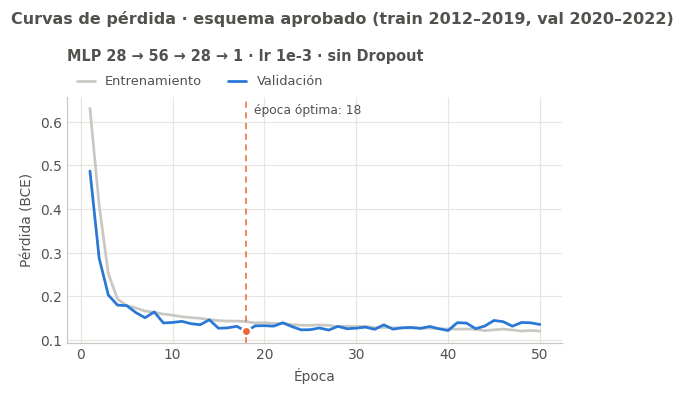

Época óptima (mínimo de validación): 18 · val 0.1200 · train 0.1423
Época 50: val 0.1357 · train 0.1208


In [19]:
# Celda 17 · Entrenamiento de la línea base MLP: 50 épocas, esquema aprobado
A = conjuntos["aprobada"]
torch.manual_seed(SEMILLA)
modelo = CentinelaMLP(len(VARIABLES))
hist_base = entrenar(modelo, A["train"]["X"], A["train"]["y"], A["val"]["X"], A["val"]["y"], epocas=50, lr=1e-3)

graficar_curvas({"MLP 28 → 56 → 28 → 1 · lr 1e-3 · sin Dropout": hist_base},
                "Curvas de pérdida · esquema aprobado (train 2012–2019, val 2020–2022)")
e = hist_base["mejor_epoca"]
print(f"Época óptima (mínimo de validación): {e} · val {hist_base['val'][e-1]:.4f} · train {hist_base['train'][e-1]:.4f}")
print(f"Época 50: val {hist_base['val'][-1]:.4f} · train {hist_base['train'][-1]:.4f}")

Muestras del subconjunto reducido: 1050


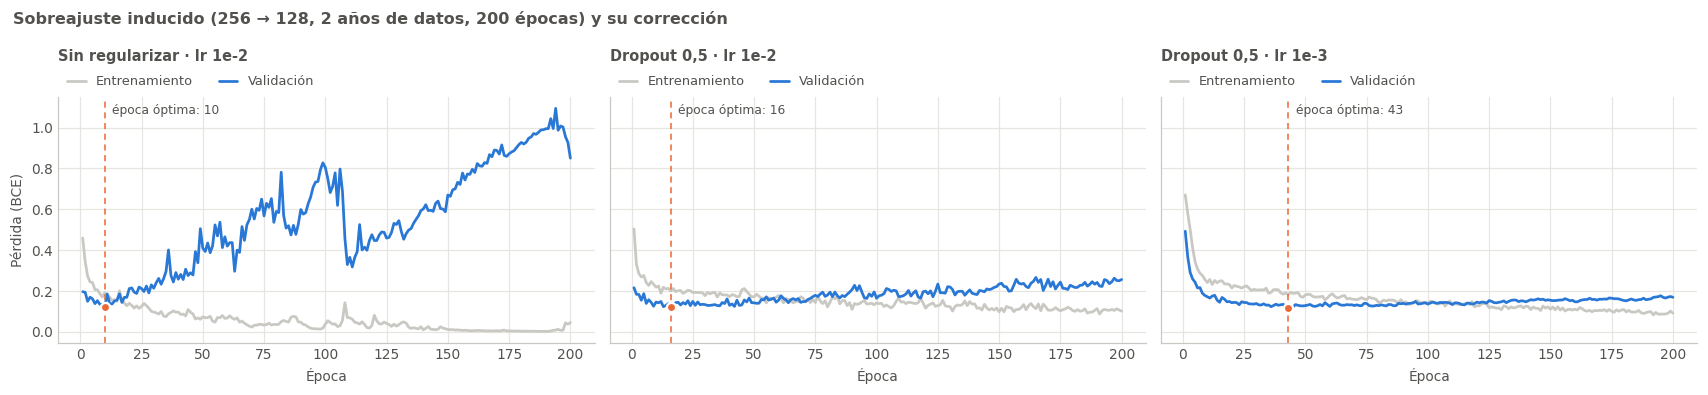

                  corrida  época óptima  val mínima  val final  train final  brecha final (val − train)
Sin regularizar · lr 1e-2            10      0.1212     0.8502       0.0444                      0.8058
    Dropout 0,5 · lr 1e-2            16      0.1213     0.2557       0.1006                      0.1551
    Dropout 0,5 · lr 1e-3            43      0.1157     0.1685       0.0907                      0.0778


In [20]:
# Celda 18 · Desafío: inducir el sobreajuste y corregirlo
# Receta para provocarlo: red mucho más grande (256 → 128), pocos datos (solo 2014–2015) y lr alto (1e-2), 200 épocas
poco = torch.tensor(A["train"]["df"]["anio_obj"].isin([2014, 2015]).to_numpy().copy())
X_poco, y_poco = A["train"]["X"][poco], A["train"]["y"][poco]
print("Muestras del subconjunto reducido:", len(X_poco))

corridas = {}
torch.manual_seed(SEMILLA)
grande = CentinelaMLP(len(VARIABLES), oculta1=256, oculta2=128, p_dropout=0.0)
corridas["Sin regularizar · lr 1e-2"] = entrenar(grande, X_poco, y_poco, A["val"]["X"], A["val"]["y"], epocas=200, lr=1e-2)

torch.manual_seed(SEMILLA)
solo_dropout = CentinelaMLP(len(VARIABLES), oculta1=256, oculta2=128, p_dropout=0.5)
corridas["Dropout 0,5 · lr 1e-2"] = entrenar(solo_dropout, X_poco, y_poco, A["val"]["X"], A["val"]["y"], epocas=200, lr=1e-2)

torch.manual_seed(SEMILLA)
corregida = CentinelaMLP(len(VARIABLES), oculta1=256, oculta2=128, p_dropout=0.5)
corridas["Dropout 0,5 · lr 1e-3"] = entrenar(corregida, X_poco, y_poco, A["val"]["X"], A["val"]["y"], epocas=200, lr=1e-3)

graficar_curvas(corridas, "Sobreajuste inducido (256 → 128, 2 años de datos, 200 épocas) y su corrección")

resumen = pd.DataFrame([{"corrida": n, "época óptima": h["mejor_epoca"], "val mínima": min(h["val"]),
                         "val final": h["val"][-1], "train final": h["train"][-1],
                         "brecha final (val − train)": h["val"][-1] - h["train"][-1]} for n, h in corridas.items()])
print(resumen.round(4).to_string(index=False))

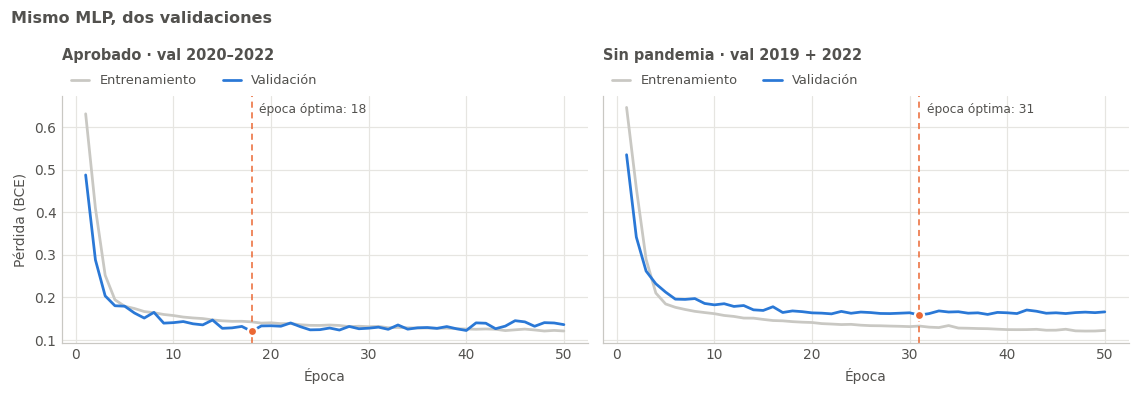

Esquema aprobado      → época óptima 18 · val mínima 0.1200
Esquema sin pandemia  → época óptima 31 · val mínima 0.1582


In [21]:
# Celda 19 · Punto 3 del profe: el mismo MLP con la validación sin pandemia (train 2012–2018, val 2019 + 2022)
S = conjuntos["sin_pandemia"]
torch.manual_seed(SEMILLA)
modelo_sp = CentinelaMLP(len(VARIABLES))
hist_sp = entrenar(modelo_sp, S["train"]["X"], S["train"]["y"], S["val"]["X"], S["val"]["y"], epocas=50, lr=1e-3)

graficar_curvas({"Aprobado · val 2020–2022": hist_base, "Sin pandemia · val 2019 + 2022": hist_sp},
                "Mismo MLP, dos validaciones")
for nombre, h in [("aprobado", hist_base), ("sin pandemia", hist_sp)]:
    print(f"Esquema {nombre:13s} → época óptima {h['mejor_epoca']:2d} · val mínima {min(h['val']):.4f}")

ROC-AUC en validación: 0.983 (no depende del umbral)
Umbral elegido (el más alto con recall ≥ 0.90 en validación): 0.306

Validación 2020–2022
 umbral  recall  precisión    F1  recall_inicio  FN  FP
  0.500   0.831      0.895 0.862          0.250  47  27
  0.350   0.881      0.863 0.872          0.477  33  39
  0.306   0.903      0.854 0.878          0.545  27  43
  0.200   0.928      0.787 0.851          0.636  20  70


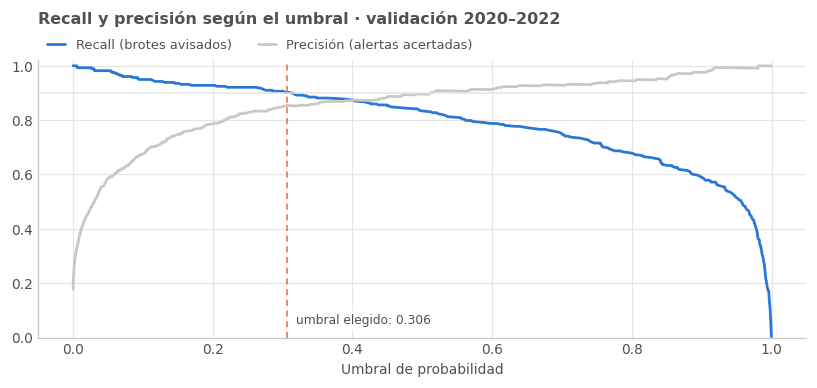

In [22]:
# Celda 20 · El umbral se elige en VALIDACIÓN (nunca en test): el más alto que avise ≥ 90 % de los brotes
from sklearn.metrics import precision_recall_curve, roc_auc_score, confusion_matrix, classification_report
RECALL_MIN = 0.90   # decisión del equipo: un brote no anticipado cuesta más que una falsa alarma

def probabilidades(modelo, X):
    modelo.eval()
    with torch.no_grad():
        return torch.sigmoid(modelo(X)).numpy().ravel()        # logit → probabilidad (la sigmoide va SOLO aquí)

def umbral_por_recall(y, prob, recall_min=RECALL_MIN):
    prec, rec, umbrales = precision_recall_curve(y, prob)
    return float(umbrales[rec[:-1] >= recall_min].max()), prec, rec, umbrales

prob_val = probabilidades(modelo, A["val"]["X"])
y_val = A["val"]["df"]["y"].values
UMBRAL, prec, rec, umbrales = umbral_por_recall(y_val, prob_val)
print(f"ROC-AUC en validación: {roc_auc_score(y_val, prob_val):.3f} (no depende del umbral)")
print(f"Umbral elegido (el más alto con recall ≥ {RECALL_MIN:.2f} en validación): {UMBRAL:.3f}\n")

filas = []
for u in sorted({0.50, 0.35, 0.20, round(UMBRAL, 3)}, reverse=True):
    m = metricas(A["val"]["df"], prob_val >= u)
    vn, fp, fn, vp = confusion_matrix(y_val, (prob_val >= u).astype(int), labels=[0, 1]).ravel()
    filas.append({"umbral": u, "recall": m["recall"], "precisión": m["precisión"], "F1": m["F1"],
                  "recall_inicio": m["recall_inicio"], "FN": fn, "FP": fp})
print("Validación 2020–2022")
print(pd.DataFrame(filas).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(umbrales, rec[:-1], color=AZUL, lw=1.8, label="Recall (brotes avisados)")
ax.plot(umbrales, prec[:-1], color=GRIS, lw=1.8, label="Precisión (alertas acertadas)")
ax.axvline(UMBRAL, color=NARANJA, lw=1, ls=(0, (4, 3)))
ax.axhline(RECALL_MIN, color=REJILLA, lw=1)
ax.annotate(f"umbral elegido: {UMBRAL:.3f}", (UMBRAL, 0.05), xytext=(6, 0), textcoords="offset points",
            fontsize=8, color=TINTA, bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.9))
ax.set_xlabel("Umbral de probabilidad"); ax.set_ylim(0, 1.02)
ax.set_title("Recall y precisión según el umbral · validación 2020–2022", pad=24)
ax.legend(loc="lower left", ncol=2, bbox_to_anchor=(0, 1.0), borderaxespad=0.3, handlelength=1.4)
plt.tight_layout(); plt.show()

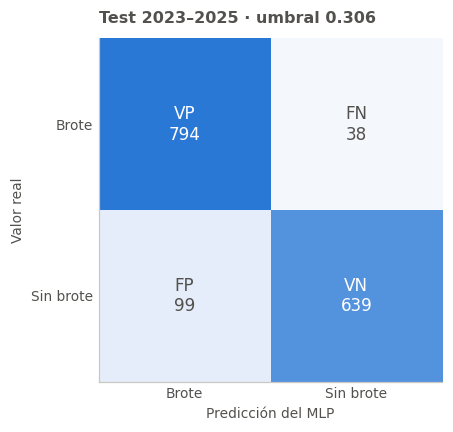

              precision    recall  f1-score   support

   Sin brote      0.944     0.866     0.903       738
       Brote      0.889     0.954     0.921       832

    accuracy                          0.913      1570
   macro avg      0.917     0.910     0.912      1570
weighted avg      0.915     0.913     0.912      1570

ROC-AUC en test: 0.979
Brotes reales: 832 · avisados (VP): 794 · NO avisados (FN): 38  ← el error caro
Falsas alarmas (FP): 99 → 3.3 por municipio y año  ← el error que desgasta la confianza

Test 2023–2025
                                      modelo  exactitud  precisión  recall    F1  recall_inicio  n_inicios
             Clase mayoritaria (nunca brote)      0.470      0.000   0.000 0.000          0.000         73
                                Persistencia      0.906      0.911   0.912 0.912          0.000         73
       MLP · esquema aprobado (umbral 0.306)      0.913      0.889   0.954 0.921          0.575         73
MLP · validación sin pandemia (umbral 

In [23]:
# Celda 21 · Evaluación en TEST (2023–2025): una sola vez, con el umbral fijado en validación
import matplotlib
T = A["test"]["df"]
prob_test = probabilidades(modelo, A["test"]["X"])
y_test, y_pred = T["y"].values, (prob_test >= UMBRAL).astype(int)

# Matriz de confusión con la clase positiva primero (como la Figura 5 de la actividad)
cm = confusion_matrix(y_test, y_pred, labels=[1, 0])
siglas = [["VP", "FN"], ["FP", "VN"]]
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap=matplotlib.colors.LinearSegmentedColormap.from_list("azules", ["#f4f8fd", AZUL]))
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{siglas[i][j]}\n{cm[i, j]:,}".replace(",", "."), ha="center", va="center", fontsize=11,
                color="white" if cm[i, j] > cm.max() / 2 else TINTA)
ax.set_xticks([0, 1], ["Brote", "Sin brote"]); ax.set_yticks([0, 1], ["Brote", "Sin brote"])
ax.set_xlabel("Predicción del MLP"); ax.set_ylabel("Valor real"); ax.grid(False)
ax.set_title(f"Test 2023–2025 · umbral {UMBRAL:.3f}")
plt.tight_layout(); plt.show()

print(classification_report(y_test, y_pred, target_names=["Sin brote", "Brote"], digits=3))
print(f"ROC-AUC en test: {roc_auc_score(y_test, prob_test):.3f}")
(vp, fn), (fp, vn) = cm
print(f"Brotes reales: {vp + fn} · avisados (VP): {vp} · NO avisados (FN): {fn}  ← el error caro")
print(f"Falsas alarmas (FP): {fp} → {fp / 10 / 3:.1f} por municipio y año  ← el error que desgasta la confianza\n")

# Comparación con las líneas base, en el mismo test
S_T = S["test"]["df"]
umbral_sp, *_ = umbral_por_recall(S["val"]["df"]["y"].values, probabilidades(modelo_sp, S["val"]["X"]))
comparacion = pd.DataFrame([
    {"modelo": "Clase mayoritaria (nunca brote)", **metricas(T, np.zeros(len(T)))},
    {"modelo": "Persistencia", **metricas(T, T["brote_t_min5"])},
    {"modelo": f"MLP · esquema aprobado (umbral {UMBRAL:.3f})", **metricas(T, y_pred)},
    {"modelo": f"MLP · validación sin pandemia (umbral {umbral_sp:.3f})",
     **metricas(S_T, probabilidades(modelo_sp, S["test"]["X"]) >= umbral_sp)},
])
print("Test 2023–2025")
print(comparacion.round(3).to_string(index=False))

In [24]:
# Celda 22 · Métricas por municipio en test (punto 2 del profe): ¿a quién le falla el modelo?
filas = []
for mun, df in T.assign(pred=y_pred).groupby("municipio"):
    m_mlp, m_per = metricas(df, df["pred"]), metricas(df, df["brote_t_min5"])
    filas.append({"municipio": mun, "brotes": int(df["y"].sum()), "inicios": m_mlp["n_inicios"],
                  "recall MLP": m_mlp["recall"], "precisión MLP": m_mlp["precisión"], "F1 MLP": m_mlp["F1"],
                  "recall_inicio MLP": m_mlp["recall_inicio"], "F1 persistencia": m_per["F1"]})
por_municipio = pd.DataFrame(filas).sort_values("recall MLP")
print(por_municipio.round(3).to_string(index=False))

    municipio  brotes  inicios  recall MLP  precisión MLP  F1 MLP  recall_inicio MLP  F1 persistencia
       Itagüí       5        3       0.800          0.200   0.320              0.667            0.400
Villavicencio     104       14       0.904          0.870   0.887              0.429            0.870
       Cúcuta      97        9       0.918          0.947   0.932              0.222            0.907
       Ibagué      81        7       0.926          0.893   0.909              0.429            0.908
        Neiva      93        9       0.957          0.890   0.922              0.556            0.903
     Medellín      89        9       0.966          0.915   0.940              0.778            0.899
 Barranquilla      71        9       0.972          0.812   0.885              0.778            0.867
  Bucaramanga     118        3       0.975          0.975   0.975              0.333            0.975
     Montería      89        8       0.989          0.854   0.917              0.8

## Anexo B · Procedencia de los datos

Punto 1 de la aprobación de la Propuesta. Cada archivo descargado queda registrado con su URL, fecha y huella SHA-256: si alguien vuelve a correr el cuaderno y obtiene la misma huella, tiene exactamente los mismos datos. La celda también hace el equivalente a un `grep` de «kaggle» sobre las URL descargadas y sobre el código del cuaderno, para dejar constancia de que no se usó ningún conjunto de Kaggle (las dos coincidencias en Kaggle que se encontraron al buscar fuentes están declaradas y contrastadas en el Anexo B de la Propuesta).

In [25]:
# Celda 23 · Anexo B · Procedencia de los datos y verificación de que no se usó Kaggle (punto 1 del profe)
import re
FUENTES = {"portalsivigila.ins.gov.co": "SIVIGILA · INS (eventos 210 y 220)",
           "power.larc.nasa.gov": "NASA POWER · clima diario",
           "raw.githubusercontent.com/TRACE-LAC": "DANE · proyecciones de población (vía sivirep)",
           "physionet.org": "PhysioNet 1.0.0 · Sentinel-2 (muestra)"}
tabla_procedencia = pd.DataFrame(procedencia)
tabla_procedencia["fuente"] = tabla_procedencia["url"].map(
    lambda u: next((f for clave, f in FUENTES.items() if clave in u), "OTRA (revisar)"))

print("Resumen por fuente")
print(tabla_procedencia.groupby("fuente").agg(archivos=("archivo", "size"),
                                              fecha_descarga=("fecha_descarga", lambda s: ", ".join(sorted(set(s)))))
      .to_string())

print("\nSHA-256 completo del clima y de la imagen")
detalle = tabla_procedencia[tabla_procedencia["fuente"].str.startswith(("NASA", "PhysioNet"))]
for _, f in detalle.iterrows():
    print(f"{f['archivo']:<55} {f['fecha_descarga']}  {f['sha256']}")
assert len(detalle) == 11, "Faltan huellas: deben ser 10 archivos de clima + 1 imagen"

# Búsqueda de "kaggle" (equivalente a un grep): en las URL descargadas y en el código del cuaderno
en_urls = int(tabla_procedencia["url"].str.contains("kaggle", case=False).sum())
print(f"\nURL descargadas que contienen «kaggle»: {en_urls} de {len(tabla_procedencia)}")
try:
    from google.colab import _message
    cuaderno = _message.blocking_request("get_ipynb", timeout_sec=60)["ipynb"]
    codigo = ["".join(c["source"]) if isinstance(c["source"], list) else c["source"]
              for c in cuaderno["cells"] if c["cell_type"] == "code"]
    con_kaggle = [s.splitlines()[0] for s in codigo if re.search("kaggle", s, re.I) and "Celda 23" not in s]
    print(f"Celdas de código que mencionan «kaggle» (sin contar esta): {len(con_kaggle)} de {len(codigo) - 1}")
    for primera_linea in con_kaggle:
        print("   →", primera_linea)
except Exception as e:
    print("No se pudo leer el cuaderno desde Colab:", e)

Resumen por fuente
                                                archivos fecha_descarga
fuente                                                                 
DANE · proyecciones de población (vía sivirep)        19     2026-11-03
NASA POWER · clima diario                             10     2026-11-03
PhysioNet 1.0.0 · Sentinel-2 (muestra)                 1     2026-11-03
SIVIGILA · INS (eventos 210 y 220)                    38     2026-11-03

SHA-256 completo del clima y de la imagen
nasa_power_05001.json                                   2026-11-03  ff3e4624dd1e243e67071cb58f3b2acaa2a13448366bc7b20f89634a1afa50bb
nasa_power_05360.json                                   2026-11-03  c1a72c36422c3126e3fcb7daa09b63054dbc2d26ef94eaa926963123194b6635
nasa_power_08001.json                                   2026-11-03  a8a47524c4bccebbdc4c24a9cd163d3e489a0ee0f957e88b4654bfb717cdde13
nasa_power_23001.json                                   2026-11-03  1b865a162e60a3fcc177b279bac52b2dc954f22

## Auditoría a la IA · E-4: el evento 580 contado como caso

**Tipo: real.** La primera versión del script de descarga (escrita con Claude) contaba como caso los eventos 210 (dengue), 220 (dengue grave) y 580 (mortalidad por dengue). Una muerte por dengue ya está notificada como caso 210 o 220, así que el 580 la contaba dos veces. Se detectó al revisar la tabla de eventos y se corrigió (`# E-4` en el script de R y en la celda 2).

**Reproducción.** Se descargan los archivos del evento 580, se arma la serie como la proponía la IA y se pasa por la misma tubería que el modelo final (canal, etiqueta, variables, partición, misma semilla, mismo criterio de umbral). Las dos versiones se miden en el test contra la etiqueta correcta. Antes, una corrida de control confirma que la tubería de la auditoría reproduce exactamente el modelo de las celdas 17–21.

In [26]:
# Celda 24 · Auditoría E-4 (1/2): descargar el evento 580 (mortalidad por dengue) que la IA incluía en la primera versión
def archivos_580(anio):
    consulta = (f"web/lists/GetByTitle('Microdatos')/items?$select=NombreEvento,A_x00f1_o,FileRef"
                f"&$filter=A_x00f1_o%20eq%20%27{anio}%27&$top=5000")
    r = requests.get(BASE + consulta, headers={"Accept": "application/json;odata=verbose"}, timeout=120)
    r.raise_for_status()
    return [it["FileRef"] for it in r.json()["d"]["results"]
            if "mortalidad" in it["NombreEvento"].lower() and "dengue" in it["NombreEvento"].lower()]

partes_580, anios_sin_archivo = [], []
for anio in ANIOS:
    rutas = archivos_580(anio)
    if not rutas:
        anios_sin_archivo.append(anio)
    for ruta in rutas:
        url = BASE + f"Web/GetFileByServerRelativeUrl('{ruta}')/$value?binaryStringResponseBody=true"
        contenido = requests.get(url, timeout=600).content
        registrar(ruta.split("/")[-1], url, contenido)
        df = leer_excel(contenido)
        df.columns = [normalizar(c) for c in df.columns]
        assert set(COLUMNAS) <= set(df.columns), f"Faltan columnas en {ruta}"
        df["ajuste"] = df["ajuste"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
        df = df[~df["ajuste"].isin(["6", "D"])]
        df["divipola"] = (pd.to_numeric(df["cod_dpto_o"], errors="coerce").astype("Int64").astype(str).str.zfill(2)
                          + pd.to_numeric(df["cod_mun_o"], errors="coerce").astype("Int64").astype(str).str.zfill(3))
        df = df[df["divipola"].isin(MUNICIPIOS["divipola"])]
        df["anio"] = pd.to_numeric(df["ano"], errors="coerce").astype(int)
        df["semana"] = pd.to_numeric(df["semana"], errors="coerce").astype(int)
        partes_580.append(df.groupby(["divipola", "anio", "semana"]).size().rename("casos_580").reset_index())
        del df, contenido                                                      # se descartan los microdatos

conteos_580 = pd.concat(partes_580).groupby(["divipola", "anio", "semana"], as_index=False)["casos_580"].sum()
print("Años sin archivo del evento 580 en el portal:", anios_sin_archivo or "ninguno")
print("\nMuertes por dengue (evento 580) que la versión de la IA sumaba como casos, 2007–2025:")
resumen_580 = (conteos_580.groupby("divipola")["casos_580"].sum()
               .reindex(MUNICIPIOS["divipola"], fill_value=0).to_frame()
               .join(MUNICIPIOS.set_index("divipola")["municipio"])
               .join(serie.groupby("divipola")["casos"].sum().rename("casos_210_220")))
resumen_580["% sobre los casos"] = (100 * resumen_580["casos_580"] / resumen_580["casos_210_220"]).round(3)
print(resumen_580.to_string())

Años sin archivo del evento 580 en el portal: ninguno

Muertes por dengue (evento 580) que la versión de la IA sumaba como casos, 2007–2025:
          casos_580      municipio  casos_210_220  % sobre los casos
divipola                                                            
05001            40       Medellín          57343              0.070
05360             2         Itagüí           8476              0.024
08001            35   Barranquilla          48572              0.072
23001            17       Montería          20752              0.082
41001            33          Neiva          39613              0.083
50001            56  Villavicencio          54620              0.103
54001            71         Cúcuta          52647              0.135
68001            44    Bucaramanga          58808              0.075
73001            69         Ibagué          58367              0.118
76001           128           Cali         164047              0.078


In [27]:
# Celda 25 · Auditoría E-4 (2/2): misma tubería, misma semilla, con y sin el 580; se mide en el test con la etiqueta correcta
COLS_BASE = ["divipola", "anio", "semana", "casos", "t2m", "t2m_max", "t2m_min", "rh2m", "lluvia", "poblacion", "municipio"]

def preparar(base):
    """Repite las celdas 7, 8, 12 y 13 (incidencia → canal → etiqueta → variables → partición aprobada)."""
    d = base[COLS_BASE].sort_values(["divipola", "anio", "semana"]).reset_index(drop=True)
    d["incidencia"] = 100_000 * d["casos"] / d["poblacion"]
    d["semana_ref"] = d["semana"].clip(upper=52)
    piv = d.pivot_table(index=["divipola", "semana_ref"], columns="anio", values="incidencia", aggfunc="mean")
    def q3(f):
        previos = [a for a in range(f.anio - VENTANA_ANIOS, f.anio) if a in piv.columns]
        return np.nan if len(previos) < VENTANA_ANIOS else np.nanpercentile(piv.loc[(f.divipola, f.semana_ref), previos].values, 75)
    d["q3_canal"] = d.apply(q3, axis=1)
    d["brote_t_min5"] = ((d["incidencia"] > d["q3_canal"]) & (d["casos"] >= MIN_CASOS)).astype(float).where(d["q3_canal"].notna())
    g = d.groupby("divipola")
    d[ETIQUETA] = g["brote_t_min5"].shift(-1)
    d["log_inc"] = np.log1p(d["incidencia"])
    for k in range(1, 5):
        d[f"log_inc_l{k}"] = g["log_inc"].shift(k)
    d["log_q3_t1"] = np.log1p(g["q3_canal"].shift(-1))
    d["anio_obj"] = g["anio"].shift(-1)
    for var in ["t2m", "rh2m", "lluvia"]:
        for desde in (0, 4, 8):
            d[f"{var}_v{desde}"] = g[var].transform(lambda s, k=desde: s.shift(k).rolling(4).mean())
    d["sem_sin"], d["sem_cos"] = np.sin(2 * np.pi * d["semana"] / 52), np.cos(2 * np.pi * d["semana"] / 52)
    d = pd.concat([d, pd.get_dummies(d["municipio"], prefix="mun", dtype=float)], axis=1)
    d = d.dropna(subset=[ETIQUETA] + VARIABLES).copy()
    d["y"] = d[ETIQUETA].astype(int)
    partes = {k: d[d["anio_obj"].isin(list(v))] for k, v in PARTICIONES["aprobada"].items()}
    media, desv = partes["train"][VARS_CONTINUAS].mean(), partes["train"][VARS_CONTINUAS].std()
    salida = {}
    for k, df in partes.items():
        X = pd.concat([(df[VARS_CONTINUAS] - media) / desv, df[VARS_BINARIAS]], axis=1)[VARIABLES]
        salida[k] = {"df": df, "X": torch.tensor(X.values, dtype=torch.float32),
                     "y": torch.tensor(df["y"].values, dtype=torch.float32).view(-1, 1)}
    return salida

CLAVE = ["divipola", "anio", "semana"]
def correr(nombre, conj):
    """Entrena con la misma semilla, fija el umbral con SU validación y evalúa contra la etiqueta CORRECTA del test."""
    torch.manual_seed(SEMILLA)
    m = CentinelaMLP(len(VARIABLES))
    h = entrenar(m, conj["train"]["X"], conj["train"]["y"], conj["val"]["X"], conj["val"]["y"], epocas=50, lr=1e-3)
    u, *_ = umbral_por_recall(conj["val"]["df"]["y"].values, probabilidades(m, conj["val"]["X"]))
    prob = (conj["test"]["df"][CLAVE].assign(p=probabilidades(m, conj["test"]["X"]))
            .set_index(CLAVE)["p"].reindex(pd.MultiIndex.from_frame(T[CLAVE])).values)
    etiquetas_distintas = sum(int((conj[k]["df"].set_index(CLAVE)["y"]
                                   != A[k]["df"].set_index(CLAVE)["y"].reindex(conj[k]["df"].set_index(CLAVE).index)).sum())
                              for k in ["train", "val", "test"])
    m_test = metricas(T, prob >= u)
    vn, fp, fn, vp = confusion_matrix(T["y"], (prob >= u).astype(int), labels=[0, 1]).ravel()
    return {"versión": nombre, "etiquetas distintas a la correcta": etiquetas_distintas, "época óptima": h["mejor_epoca"],
            "umbral": round(u, 3), "AUC test": roc_auc_score(T["y"], prob), "recall": m_test["recall"],
            "precisión": m_test["precisión"], "F1": m_test["F1"], "recall_inicio": m_test["recall_inicio"],
            "FN": fn, "FP": fp}, prob

# Control: la función tiene que reproducir EXACTAMENTE el modelo de las celdas 17–21
conj_ok = preparar(datos)
fila_ok, prob_ok = correr("Corregida (210 + 220)", conj_ok)
print("Control · ¿la tubería de la auditoría reproduce el modelo del cuaderno?", bool(np.allclose(prob_ok, prob_test)))

# Versión de la IA: los casos incluyen el evento 580
datos_ia = (datos[COLS_BASE].merge(conteos_580, on=CLAVE, how="left").fillna({"casos_580": 0})
            .assign(casos=lambda d: d["casos"] + d["casos_580"].astype(int)))
conj_ia = preparar(datos_ia)
fila_ia, prob_ia = correr("Versión de la IA (210 + 220 + 580)", conj_ia)

auditoria = pd.DataFrame([fila_ia, fila_ok])
print("\nTest 2023–2025, siempre medido contra la etiqueta correcta (210 + 220)")
print(auditoria.round(4).to_string(index=False))
print(f"\nDiferencia en AUC: {fila_ia['AUC test'] - fila_ok['AUC test']:+.4f} · en recall: {fila_ia['recall'] - fila_ok['recall']:+.4f}"
      f" · en recall_inicio: {fila_ia['recall_inicio'] - fila_ok['recall_inicio']:+.4f}")

Control · ¿la tubería de la auditoría reproduce el modelo del cuaderno? True

Test 2023–2025, siempre medido contra la etiqueta correcta (210 + 220)
                           versión  etiquetas distintas a la correcta  época óptima  umbral  AUC test  recall  precisión     F1  recall_inicio  FN  FP
Versión de la IA (210 + 220 + 580)                                  5            18   0.311    0.9790  0.9555     0.8883 0.9207         0.5890  37 100
             Corregida (210 + 220)                                  0            18   0.306    0.9789  0.9543     0.8891 0.9206         0.5753  38  99

Diferencia en AUC: +0.0001 · en recall: +0.0012 · en recall_inicio: +0.0137
